[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_autosc.ipynb)


# Auto-oscillations

A self-sustained oscillation is a stable periodic regime whose amplitude and period are selected by the system’s internal nonlinear dynamics rather than by a periodic external force. Free oscillations decay through friction; forced oscillations follow an imposed rhythm; a self-oscillator draws energy from a steady source and regulates that input during every cycle. It is therefore the simplest temporal structure in an open dissipative system. Simple mathematical models of self-oscillators involve negative linear damping and positive non-linear damping terms. The van der Pol oscillator is one such model that has been used extensively in the mathematical literature. Self-oscillations are important in physics, engineering, biology, and economics. (from Wiki)

### Phase portraits and fixed points

An autonomous system defines a vector field in the plane:

$$
\dot{x}=f\left(x,y\right),    \dot{y}=g\left(x,y\right).
$$

At each state, the vector gives the direction and rate of motion. A phase portrait shows representative trajectories with arrows pointing forward in time. For a mechanical oscillator the coordinates can be displacement and velocity; for an ecosystem they can be two population densities. A time trace shows change with time, whereas a phase portrait shows the relation between state variables. For a smooth autonomous field, distinct trajectories cannot cross at a regular point, by uniqueness of solutions.

A fixed point, or equilibrium, is a state at which both derivatives vanish. A nullcline is a curve where one derivative vanishes: on the x-nullcline the flow is vertical, and on the y-nullcline it is horizontal. Intersections of the nullclines are equilibria. A nullcline generally is not itself a trajectory.

An equilibrium is Lyapunov stable if sufficiently small initial perturbations remain small for all future time. It is asymptotically stable if they also tend to zero. A center may therefore be stable without attracting nearby states. A stable limit cycle instead attracts nearby trajectories to a periodic orbit, with a possible phase shift.

### Linearization and classification

Near an equilibrium, retain terms linear in the displacement from it. Evaluate the Jacobian at that equilibrium:

$$
J=\left(\begin{matrix}{f}_{x} & {f}_{y}\\ {g}_{x} & {g}_{y}\end{matrix}\right),    \tau =trJ,  \Delta =detJ,  D={\tau }^{2}-4\Delta .
$$

The eigenvalues obey

$$
{\lambda }^{2}-\tau \lambda +\Delta =0,    {\lambda }_{1,2}=\frac{\tau \pm \sqrt{D}}{2}.
$$

Stable node. $\Delta >0$, $D>0$, $\tau <0$. Two negative real eigenvalues; approach without spiralling.

Unstable node. $\Delta >0$, $D>0$, $\tau >0$. Two positive real eigenvalues; depart without spiralling.

Saddle. $\Delta <0$. Opposite real signs; one attracting and one repelling eigendirection.

Stable focus (spiral sink). $\Delta >0$, $D<0$, $\tau <0$. Negative real parts; inward spirals.

Unstable focus (spiral source). $\Delta >0$, $D<0$, $\tau >0$. Positive real parts; outward spirals.

Centre. $\Delta >0$, $\tau =0$. Purely imaginary pair; closed orbits in the linear system.

For $D=0$, a nonzero repeated eigenvalue gives a star node with two independent eigenvectors, or an improper node with only one. If an eigenvalue has zero real part, including a purely imaginary pair or $\Delta =0$, linearization alone does not decide nonlinear stability. Adding inward or outward cubic radial drift to a linear centre changes its stability without changing its Jacobian. A conserved quantity will establish the nonlinear centre in the Lotka–Volterra example below.

An equilibrium is hyperbolic when no eigenvalue has zero real part. For a smooth nonlinear field, negative real parts imply local asymptotic stability; a positive real part implies instability. The saddle structure persists locally. These local conclusions do not by themselves establish a distant limit cycle.

Stable node: eigenvalues [-1.+0.j -2.+0.j]
Unstable node: eigenvalues [1.+0.j 2.+0.j]
Saddle: eigenvalues [ 1.+0.j -1.+0.j]
Stable focus: eigenvalues [-0.3+1.j -0.3-1.j]
Unstable focus: eigenvalues [0.3+1.j 0.3-1.j]
Centre: eigenvalues [0.+1.j 0.-1.j]


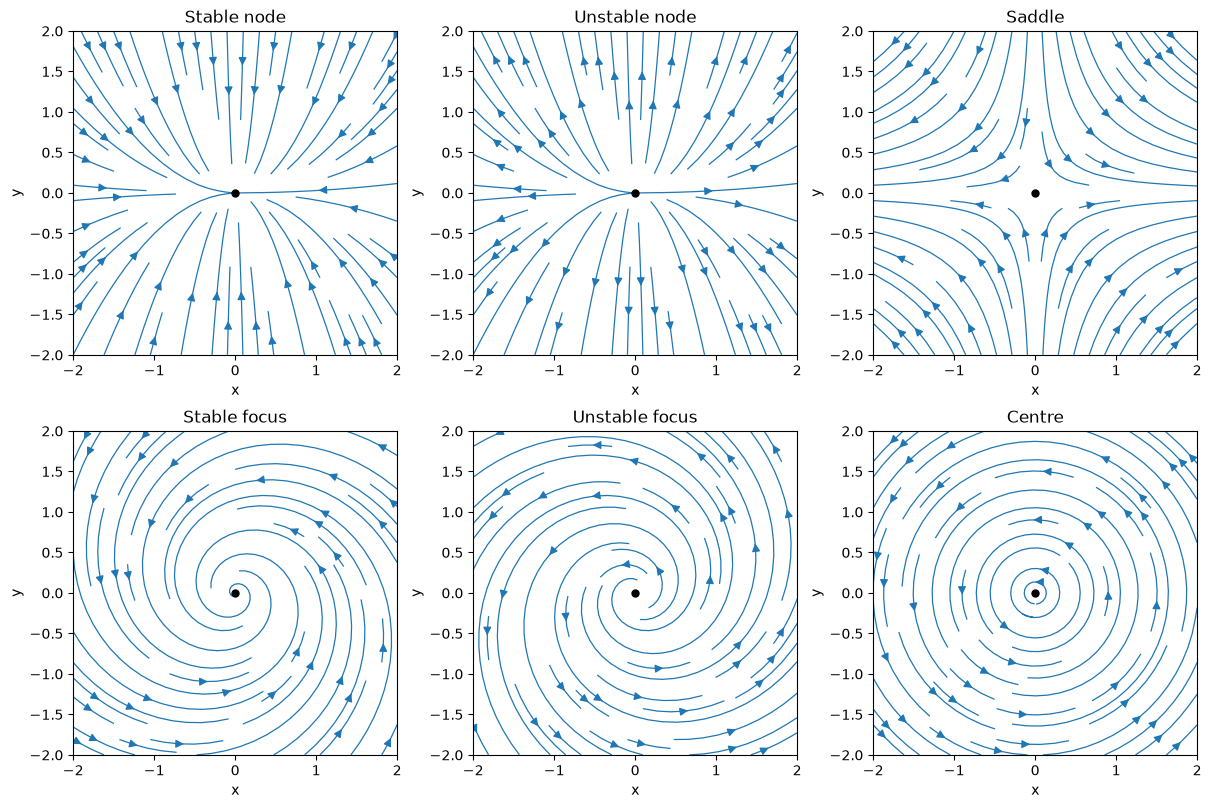

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import display

phase_matrices = {
    'Stable node': np.array([[-1, 0], [0, -2]]),
    'Unstable node': np.array([[1, 0], [0, 2]]),
    'Saddle': np.array([[1, 0], [0, -1]]),
    'Stable focus': np.array([[-0.3, -1], [1, -0.3]]),
    'Unstable focus': np.array([[0.3, -1], [1, 0.3]]),
    'Centre': np.array([[0, -1], [1, 0]]),
}
phase_grid = np.linspace(-2, 2, 75)
phase_x, phase_y = np.meshgrid(phase_grid, phase_grid)
fig, axes = plt.subplots(2, 3, figsize=(12, 8), layout='constrained')
for ax, (name, matrix) in zip(axes.flat, phase_matrices.items()):
    fx = matrix[0, 0]*phase_x + matrix[0, 1]*phase_y
    fy = matrix[1, 0]*phase_x + matrix[1, 1]*phase_y
    ax.streamplot(phase_grid, phase_grid, fx, fy, density=0.75,
                  color='C0', linewidth=0.9, arrowsize=1.2)
    ax.plot(0, 0, 'ko', ms=5)
    ax.set(title=name, xlabel='x', ylabel='y', aspect='equal', xlim=(-2, 2), ylim=(-2, 2))
    print(f'{name}: eigenvalues {np.linalg.eigvals(matrix)}')
plt.show()

### Reading the van der Pol phase portrait

For the van der Pol oscillator, the standard equation is 

$$\ddot x-\mu\left(1-x^2\right)\dot x+x=0.$$

For displacement and velocity as coordinates, the Jacobian at the origin is

$$
{J}_{0}=\left(\begin{matrix}0 & 1\\ -1 & \mu \end{matrix}\right),    {\lambda }_{1,2}=\frac{\mu \pm \sqrt{{\mu }^{2}-4}}{2}.
$$

For $0<\mu <2$ the origin is an unstable focus; for $\mu >2$ it is an unstable node, with an improper node at $\mu =2$. In both positive-parameter regimes the nonlinear damping supports an attracting periodic orbit. The fixed point and the limit cycle are different invariant sets. An unstable focus alone does not prove a limit cycle exists: the dynamics away from the equilibrium must also be examined. At $\mu =0$ the equation is the harmonic oscillator, whose conserved energy gives a family of closed orbits.

A direct Python simulation is: 

Eq(mean_power, A**2*mu*(4 - A**2)/8)

Eq(dA_dt, -A*mu*(A - 2)*(A + 2)/8)

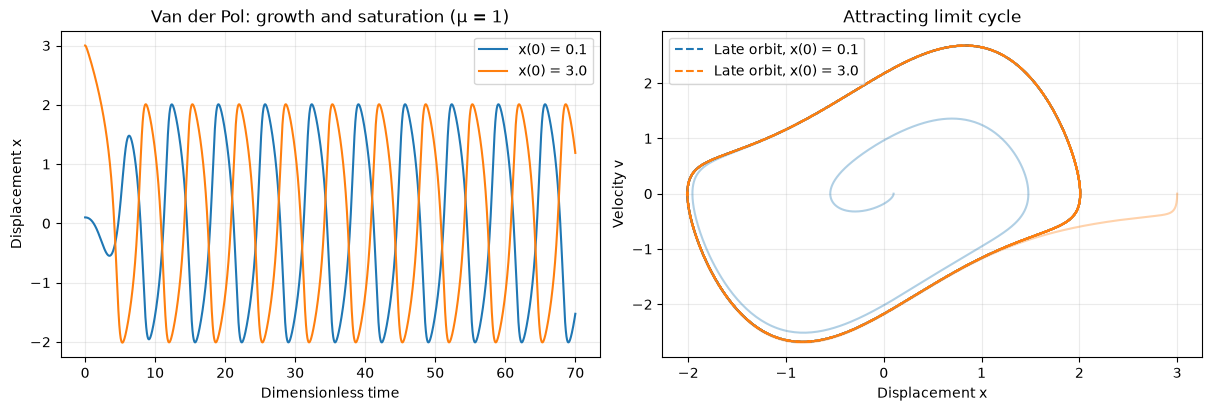

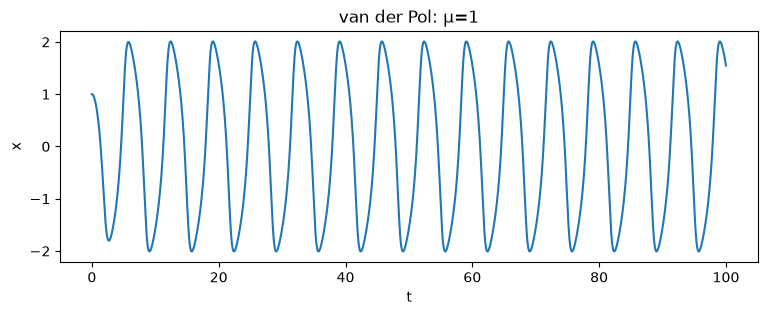

In [2]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import display

A, mu_symbol = sp.symbols('A mu', positive=True)
theta = sp.symbols('theta', real=True)
x_trial, v_trial = A*sp.cos(theta), -A*sp.sin(theta)
mean_power = sp.simplify(sp.integrate(
    mu_symbol*(1-x_trial**2)*v_trial**2,
    (theta, 0, 2*sp.pi))/(2*sp.pi))
amplitude_rate = sp.factor(mean_power/A)
assert sp.simplify(amplitude_rate-mu_symbol*A*(1-A**2/4)/2) == 0
display(sp.Eq(sp.Symbol('mean_power'), mean_power))
display(sp.Eq(sp.Symbol('dA_dt'), amplitude_rate))
def vdp_rhs(t, state, mu):
    x, v = state
    return [v, mu*(1-x*x)*v-x]

def integrate_autoosc(rhs, initial, end, args=()):
    solution = solve_ivp(rhs, (0, end), initial, args=args,
                         method='DOP853', rtol=1e-9, atol=1e-11,
                         max_step=0.05, dense_output=True)
    assert solution.success, solution.message
    return solution

vdp_transients = [integrate_autoosc(vdp_rhs, [x0, 0], 70, (1.0,))
                  for x0 in (0.1, 3.0)]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
sample_t = np.linspace(0, 70, 6000)
for solution, x0, colour in zip(vdp_transients, (0.1, 3.0), ('C0', 'C1')):
    x, v = solution.sol(sample_t)
    axes[0].plot(sample_t, x, color=colour, label=f'x(0) = {x0}')
    axes[1].plot(x, v, color=colour, alpha=0.35)
    late = sample_t > 55
    axes[1].plot(x[late], v[late], '--', color=colour,
                 label=f'Late orbit, x(0) = {x0}')
axes[0].set(xlabel='Dimensionless time', ylabel='Displacement x',
            title='Van der Pol: growth and saturation (μ = 1)')
axes[1].set(xlabel='Displacement x', ylabel='Velocity v',
            title='Attracting limit cycle')
for ax in axes:
    ax.legend(); ax.grid(alpha=0.25)
plt.show()
vdp_native=integrate_autoosc(vdp_rhs,(1.0,0.0),100,(1.0,))
fig,ax=plt.subplots(figsize=(9,3)); ax.plot(vdp_native.t,vdp_native.y[0]); ax.set(xlabel="t",ylabel="x",title="van der Pol: μ=1"); plt.show()

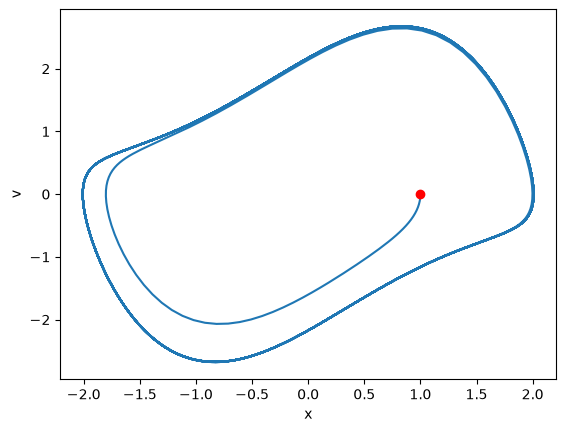

In [3]:
fig,ax=plt.subplots(); ax.plot(vdp_native.y[0],vdp_native.y[1]); ax.plot(1,0,"ro"); ax.set(xlabel="x",ylabel="v"); plt.show()

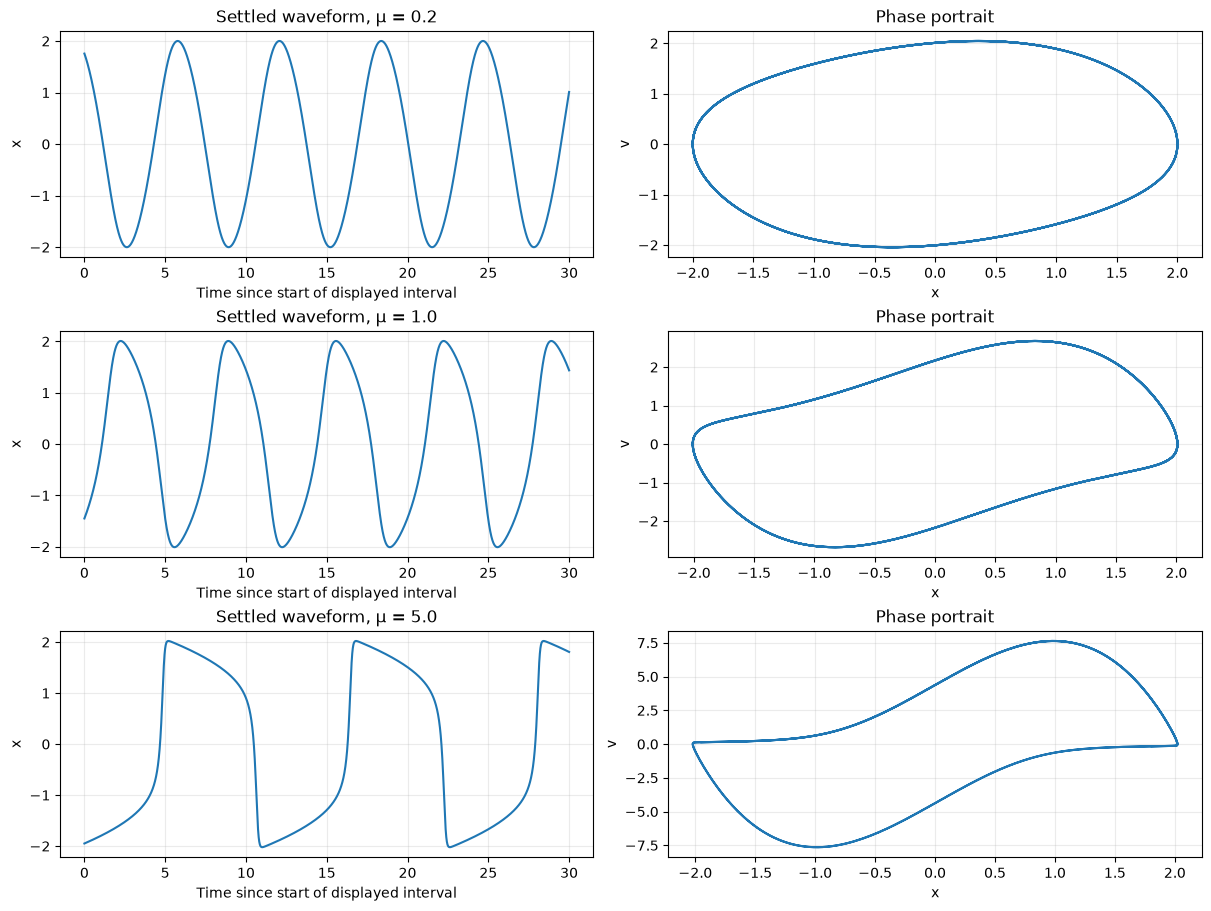

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='mu', max=5.0), FloatSlider(…

In [4]:
fig, axes = plt.subplots(3, 2, figsize=(12, 9), layout='constrained')
vdp_waveforms = {}
for row, mu_value in enumerate((0.2, 1.0, 5.0)):
    end = max(100.0, 30.0/mu_value)
    solution = integrate_autoosc(vdp_rhs, [0.2, 0], end, (mu_value,))
    vdp_waveforms[mu_value] = solution
    times = np.linspace(end-30, end, 6000)
    x, v = solution.sol(times)
    axes[row, 0].plot(times-(end-30), x)
    axes[row, 0].set(xlabel='Time since start of displayed interval',
                     ylabel='x', title=f'Settled waveform, μ = {mu_value}')
    axes[row, 1].plot(x, v)
    axes[row, 1].set(xlabel='x', ylabel='v', title='Phase portrait')
    for ax in axes[row]:
        ax.grid(alpha=0.25)
plt.show()
import ipywidgets as widgets

def show_vdp(mu=1.0,x0=1.0,v0=0.0):
    solution=integrate_autoosc(vdp_rhs,(x0,v0),100,(mu,))
    times=np.linspace(0,100,5000)
    x,v=solution.sol(times)
    fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
    axes[0].plot(times,x); axes[0].set(xlabel='t',ylabel='x')
    axes[1].plot(x,v); axes[1].plot(x0,v0,'ro'); axes[1].set(xlabel='x',ylabel='v')
    for ax in axes: ax.grid(alpha=.25)
    plt.show()
widgets.interact(show_vdp,
    mu=widgets.FloatSlider(value=1,min=0,max=5,step=.1,continuous_update=False),
    x0=widgets.FloatSlider(value=1,min=-3,max=3,step=.1,continuous_update=False),
    v0=widgets.FloatSlider(value=0,min=-3,max=3,step=.1,continuous_update=False));


### Rayleigh oscillator: feedback through velocity

A related model places the nonlinear damping in the velocity:

$$
\ddot x+x=\varepsilon\left(1-\frac{\dot x^{2}}{3}\right)\dot x,
\qquad \varepsilon>0,
\qquad \dot E=\varepsilon\left(v^{2}-\frac{v^{4}}{3}\right).
$$

Here the system gains energy for $0<\left|v\right|<\sqrt{3}$ and loses energy at larger speeds. The factor $1/3$ is a normalization choice. Averaging gives the same leading amplitude equation as above, with $\mu$ replaced by $\varepsilon$, and therefore a weakly nonlinear displacement amplitude near $2$. The thresholds are different: van der Pol feedback depends on displacement, whereas Rayleigh feedback depends on velocity.

This normalization also exhibits an exact relationship: if $y$ satisfies the Rayleigh equation and $x=\dot y$, differentiation gives the van der Pol equation for $x$, with $\mu=\varepsilon$. In that correspondence the van der Pol coordinate represents the Rayleigh **velocity**. The numerical experiment below compares the two models using each one's own displacement and velocity, without identifying their coordinates.

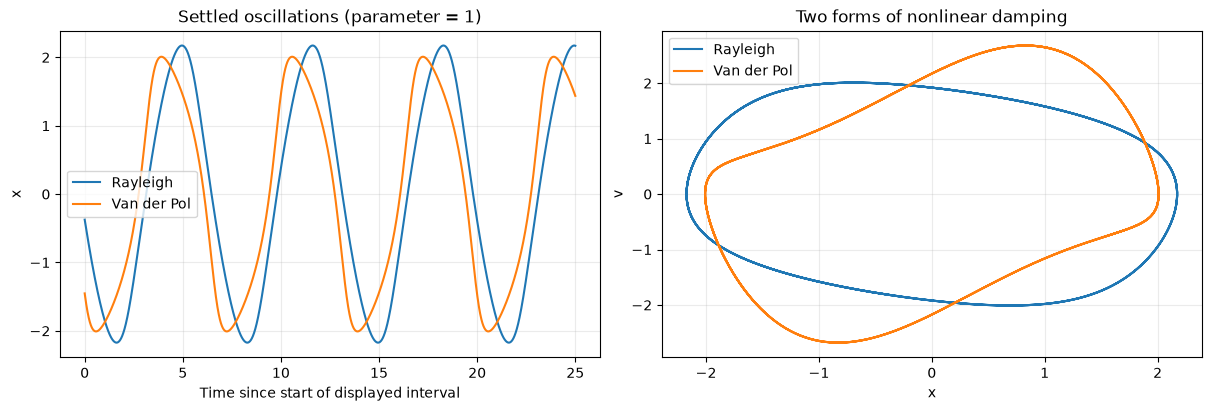

In [5]:
def rayleigh_rhs(t, state, epsilon):
    x, v = state
    return [v, epsilon*(1-v*v/3)*v-x]

rayleigh_solution = integrate_autoosc(rayleigh_rhs, [0.2, 0], 100, (1.0,))
times = np.linspace(75, 100, 6000)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
for label, solution in [('Rayleigh', rayleigh_solution),
                        ('Van der Pol', vdp_waveforms[1.0])]:
    x, v = solution.sol(times)
    axes[0].plot(times-75, x, label=label)
    axes[1].plot(x, v, label=label)
axes[0].set(xlabel='Time since start of displayed interval', ylabel='x',
            title='Settled oscillations (parameter = 1)')
axes[1].set(xlabel='x', ylabel='v', title='Two forms of nonlinear damping')
for ax in axes:
    ax.legend(); ax.grid(alpha=0.25)
plt.show()

### Common physical examples

These systems illustrate the same energy-supply and feedback principle. Their detailed equations differ; the van der Pol or Rayleigh equations are simplified models rather than universal descriptions.

| System | Steady energy supply | Feedback and amplitude limitation |
| --- | --- | --- |
| Pendulum clock with an escapement | A descending weight or wound spring | The pendulum controls the timing of small impulses. Losses and the escapement regulate the sustained motion. |
| Organ pipe or whistle | A steady air flow and pressure difference | The acoustic motion changes the air jet, allowing it to feed sound; nonlinear flow and losses limit the amplitude. |
| Bowed violin string | Mechanical work from a steadily moving bow | Alternating sticking and slipping transfer energy to the string. Friction and the string's motion regulate the cycle. |
| Active electronic oscillator | A DC power supply | An amplifying or negative-resistance element compensates losses in an oscillatory circuit. Nonlinear saturation limits the amplitude; the van der Pol model is a classical example. |

A violin string or an air column is a distributed system and can support several modes. A single-variable oscillator is useful only when one oscillatory mode dominates. Likewise, the familiar clock includes intermittent impulses rather than smooth damping.

### A minimal model near the onset of oscillation

Many systems close to a supercritical Hopf bifurcation have the following local amplitude description:

$$
\dot r=\lambda r-\beta r^{3},\qquad
\dot\theta=\omega_0-c r^{2},\qquad \beta>0.
$$

For $\lambda<0$, the amplitude decays to zero. For $\lambda>0$, a nonzero stable amplitude appears,

$$
r_*=\sqrt{\frac{\lambda}{\beta}},\qquad
\Omega=\omega_0-c\frac{\lambda}{\beta}.
$$

When $\Omega\ne0$, this amplitude describes a periodic orbit. The cubic term stabilizes its amplitude, and the coefficient $c$ permits an amplitude-dependent frequency. This is the polar form of the Stuart–Landau model, a local description near onset rather than a model for all amplitudes. The weakly nonlinear van der Pol amplitude equation corresponds to $\lambda=\mu/2$ and $\beta=\mu/8$ at leading order.

### Questions to explore

1. Use the energy equation to explain why negative **linear** damping alone cannot select a finite sustained amplitude.
2. Change the initial displacement in the van der Pol experiment. Compare the final amplitude, period, and phase after the transient.
3. Average the Rayleigh power over $x=A\cos{\theta}$ and recover the leading amplitude equation. Why does its velocity threshold not equal the final displacement amplitude?
4. Add a periodic force $F\cos{\Omega t}$ to the van der Pol equation. Identify which source sustains the autonomous oscillation and which introduces an external rhythm. Synchronization to that rhythm is a separate question from the existence of a self-oscillation.

### Ecological oscillations: the Lotka–Volterra model

Consider prey such as hares and predators such as lynx. More prey provide food for predators; the growing predator population reduces the prey; food scarcity then reduces the predators, allowing prey recovery. This feedback can generate population cycles without seasonal forcing. The model is an idealization of the mechanism, not a quantitative description of a particular ecosystem.

With prey density $N$ and predator density $P$, the classical equations are

$$
\dot{N}=αN-\beta NP,    \dot{P}=\delta NP-\gamma P,    α,\beta ,\gamma ,\delta >0.
$$

Here $αN$ is exponential prey growth without predators; $\beta NP$ is prey loss through encounters; $\delta NP$ is the resulting predator growth; and $\gamma P$ is predator mortality. The populations are assumed well mixed. Finite prey resources, predator satiation, migration, seasonal forcing and demographic noise are omitted. The prey's resource supply is implicit in its growth term.

The nullclines are the axes together with $P=α/\beta $ and $N=\gamma /\delta $. Besides the extinction equilibrium at the origin, there is a coexistence state:

$$
{N}_{*}=\frac{\gamma }{\delta },  {P}_{*}=\frac{α}{\beta },    {J}_{*}=\left(\begin{matrix}0 & -\beta \gamma /\delta \\ \delta α/\beta  & 0\end{matrix}\right),  {\lambda }_{1,2}=\pm i\sqrt{α\gamma }.
$$

The origin is a saddle with eigenvalues $α$ and $-\gamma $. At coexistence, the imaginary pair suggests oscillation but does not alone prove a nonlinear centre. Introduce scaled populations $u=N/{N}_{*}$, $v=P/{P}_{*}$ and time $s=αt$, with $r=\gamma /α$:

$$
\frac{du}{ds}=u\left(1-v\right),    \frac{dv}{ds}=rv\left(u-1\right).
$$

In the positive quadrant the first integral is

$$
H\left(u,v\right)=r\left(u-1-lnu\right)+v-1-lnv,    \frac{dH}{ds}=0.
$$

It has a unique minimum at $\left(1,1\right)$. Every positive level is a closed curve surrounding that point, bounded away from the axes and infinity. The vector field does not vanish on such a curve, so it is a periodic trajectory. Coexistence is a stable center, not an attractor. Different initial states select different orbits. The small-amplitude physical period is $2π/\sqrt{α\gamma }$; finite-amplitude periods need not equal this value.

Classical Lotka–Volterra therefore illustrates autonomous, sustained ecological oscillations. Under the stricter definition used here for self-oscillation, it lacks amplitude selection: these orbits are not isolated attracting limit cycles. 

In [6]:
lv_u, lv_v, lv_r = sp.symbols('u v r', positive=True)
lv_field = sp.Matrix([lv_u*(1-lv_v), lv_r*lv_v*(lv_u-1)])
lv_jacobian = lv_field.jacobian([lv_u, lv_v]).subs({lv_u: 1, lv_v: 1})
lv_H = lv_r*(lv_u-1-sp.log(lv_u)) + lv_v-1-sp.log(lv_v)
lv_Hdot = sp.simplify(sp.diff(lv_H, lv_u)*lv_field[0] + sp.diff(lv_H, lv_v)*lv_field[1])
assert lv_Hdot == 0
print('Coexistence Jacobian:'); display(lv_jacobian)
print('Eigenvalues:', lv_jacobian.eigenvals())
print('Derivative of the first integral:', lv_Hdot)

Coexistence Jacobian:


Matrix([
[0, -1],
[r,  0]])

Eigenvalues: {-I*sqrt(r): 1, I*sqrt(r): 1}
Derivative of the first integral: 0


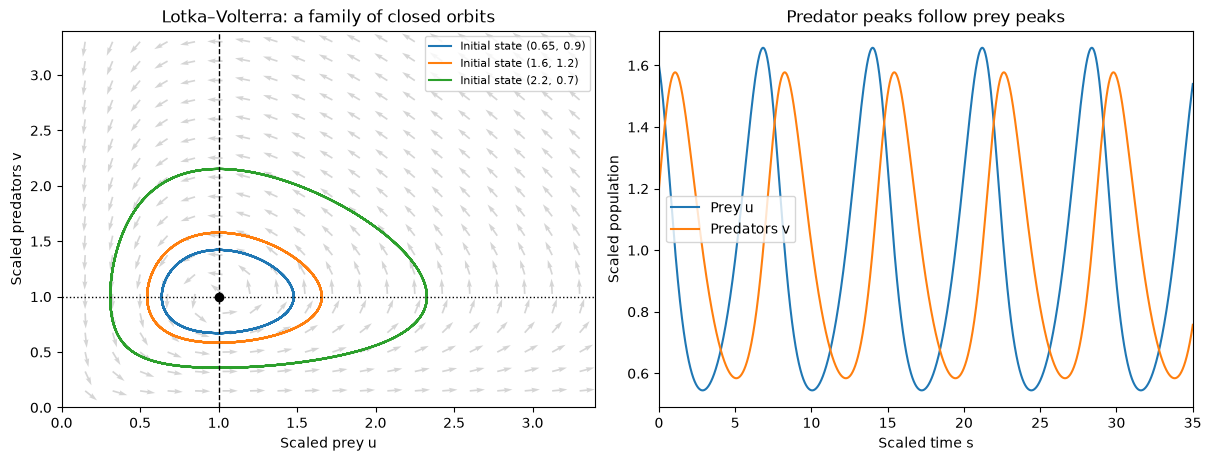

In [7]:
def lv_rhs(s, state, r=0.8):
    u, v = state
    return [u*(1-v), r*v*(u-1)]

lv_initial_states = [(0.65, 0.9), (1.6, 1.2), (2.2, 0.7)]
lv_times = np.linspace(0, 60, 6001)
lv_solutions = [solve_ivp(lv_rhs, (0, 60), initial, method='DOP853', rtol=1e-10,
                        atol=1e-12, max_step=0.05, dense_output=True)
                for initial in lv_initial_states]
assert all(sol.success and np.all(sol.y > 0) for sol in lv_solutions)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained')
for sol, initial in zip(lv_solutions, lv_initial_states):
    u, v = sol.sol(lv_times)
    invariant = 0.8*(u-1-np.log(u)) + v-1-np.log(v)
    assert np.ptp(invariant) < 1e-7
    axes[0].plot(u, v, label=f'Initial state {initial}')
grid = np.linspace(0.15, 3.3, 19)
U, V = np.meshgrid(grid, grid)
du, dv = U*(1-V), 0.8*V*(U-1)
speed = np.hypot(du, dv)
axes[0].quiver(U, V, du/np.maximum(speed, 1e-12), dv/np.maximum(speed, 1e-12),
               color='0.7', alpha=0.55, scale=35)
axes[0].axvline(1, color='black', ls='--', lw=1)
axes[0].axhline(1, color='black', ls=':', lw=1)
axes[0].plot(1, 1, 'ko')
axes[0].set(xlabel='Scaled prey u', ylabel='Scaled predators v',
            title='Lotka–Volterra: a family of closed orbits', xlim=(0, 3.4), ylim=(0, 3.4))
axes[0].legend(fontsize=8)
u, v = lv_solutions[1].sol(lv_times)
axes[1].plot(lv_times, u, label='Prey u')
axes[1].plot(lv_times, v, label='Predators v')
axes[1].set(xlabel='Scaled time s', ylabel='Scaled population',
            title='Predator peaks follow prey peaks', xlim=(0, 35))
axes[1].legend()
plt.show()

### Amplitude selection in ecology

Finite prey resources and predator satiation can produce an attracting cycle. A dimensionless Rosenzweig–MacArthur model combines logistic prey growth and a saturating predation rate:

$$
\dot{u}=u\left(1-\frac{u}{K}\right)-\frac{uv}{1+u},    \dot{v}=v\left(\frac{u}{1+u}-d\right).
$$

Here $K$ is scaled carrying capacity and $d$ is scaled predator mortality; time and both populations have been rescaled. For $d=1/2$ and $K>1$, positive coexistence occurs at

$$
{u}_{*}=1,  {v}_{*}=2\left(1-\frac{1}{K}\right),    \tau =\frac{K-3}{2K},  \Delta =\frac{K-1}{4K}.
$$

At $K=2$ the coexistence state is a stable focus and fluctuations decay. At $K=4$ it is an unstable focus and trajectories approach a stable limit cycle. Stability changes at a Hopf bifurcation at $K=3$. The trace crossing alone does not establish the direction or stability of the emerging cycle; the standard model has a supercritical Hopf bifurcation. The experiment illustrates the attracting orbit above the threshold. See André de Roos's predator–prey bifurcation notes.

This modified model selects an oscillation amplitude through nonlinear feedback, unlike the classical Lotka–Volterra family. It is an ecological self-oscillator in the attracting-limit-cycle sense. Its final phase can still depend on initial conditions. Both models are idealizations; their comparison shows how biological assumptions change the phase portrait.

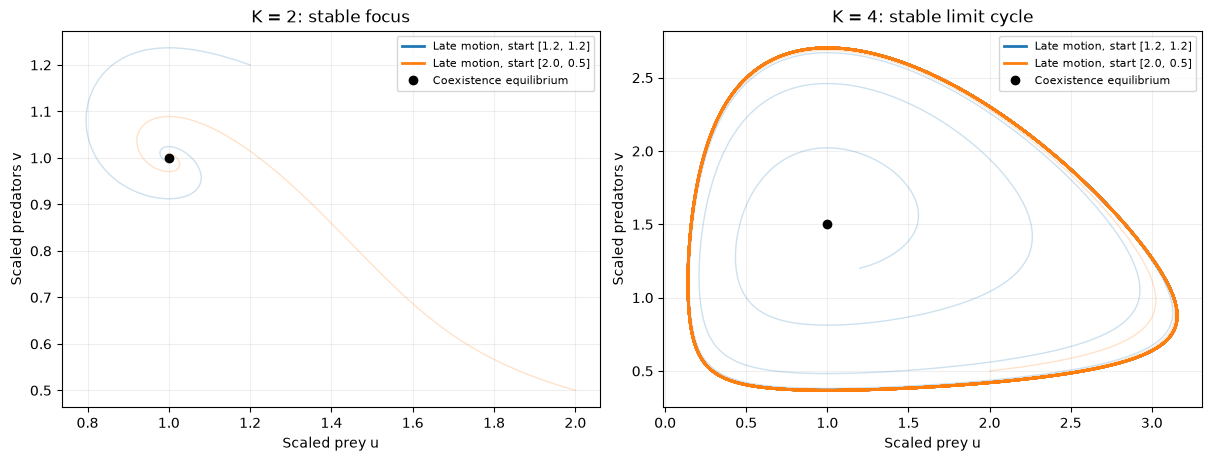

In [8]:
def ecology_rhs(t, state, K):
    u, v = state
    intake = u*v/(1+u)
    return [u*(1-u/K)-intake, intake-0.5*v]

ecology_solutions = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained')
for ax, K in zip(axes, (2.0, 4.0)):
    equilibrium = np.array([1.0, 2*(1-1/K)])
    for initial, color in zip(([1.2, 1.2], [2.0, 0.5]), ('C0', 'C1')):
        sol = solve_ivp(ecology_rhs, (0, 500), initial, args=(K,), method='DOP853',
                        rtol=1e-10, atol=1e-12, max_step=0.1, dense_output=True)
        assert sol.success and np.all(sol.y > 0)
        ecology_solutions[(K, tuple(initial))] = sol
        early = sol.sol(np.linspace(0, 500, 10000))
        late = sol.sol(np.linspace(400, 500, 3000))
        ax.plot(*early, color=color, alpha=0.22, lw=1)
        ax.plot(*late, color=color, lw=2, label=f'Late motion, start {initial}')
    ax.plot(*equilibrium, 'ko', label='Coexistence equilibrium')
    ax.set(xlabel='Scaled prey u', ylabel='Scaled predators v',
           title=f'K = {K:g}: '+('stable focus' if K == 2 else 'stable limit cycle'))
    ax.legend(fontsize=8); ax.grid(alpha=0.2)
plt.show()

### Phase-portrait exercises

1. Classify the equilibrium of $\dot{x}=y$, $\dot{y}=-x-cy$ as the damping coefficient $c$ varies, including the repeated-eigenvalue cases.

2. Explain why imaginary eigenvalues alone do not establish a nonlinear center. Identify the extra argument for Lotka–Volterra.

3. Verify the Lotka–Volterra first integral along a trajectory. Change the initial populations and compare the orbits and periods.

4. Compare the response to a small perturbation of a Lotka–Volterra orbit, a stable focus, and the stable ecological limit cycle. Which recover a selected amplitude?

5. Vary $K$ across $3$ in the modified model. Explain why a long transient near the threshold can be mistaken for a permanent oscillation.

[Back to ToC](https://colab.research.google.com/github/kulinskij-tech/ClassMech/blob/main/ClassMech_Python/classmech_TOC.ipynb)